In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
X = [1.2, 1.8, 3.1, 4.9, 5.7, 7.1, 8.6, 9.8]

y = [4.5, 5.9, 7.0, 7.8, 7.2, 6.8, 4.5, 2.7]

$$Na + b\sum_{i=1}x_{i} + c \sum_{i=1}x_{i}^{2} = \sum_{i=1}^{N}y \quad (1)$$

$$a\sum_{i=1}x_{i} + b\sum_{i=1}{x_{i}^{2}} + c\sum_{i=1}x_{i}^{3} = \sum_{i=1}x_{i}y_{i} \quad (2)$$

$$a\sum_{i=1}x_{i}^{2} + b\sum_{i=1}{x_{i}^{3}} + c\sum_{i=1}x_{i}^{4} = \sum_{i=1}x_{i}^{2}y_{i} \quad (2)$$

In [7]:
data = pd.read_csv("./2_regression_polynomiale.csv")

data

,x,y
0,-4.096,22.800
1,3.970,0.496
2,-4.710,24.010
3,-2.592,15.185
4,-3.570,13.208
...,...,...
195,-3.859,18.187
196,2.324,1.550
197,-0.599,4.466
198,0.531,1.673


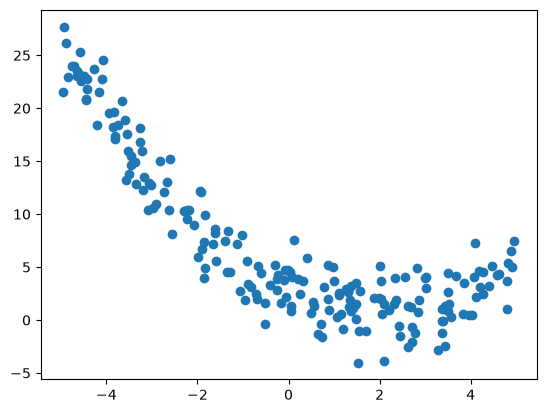

In [8]:
plt.scatter(data['x'], data['y'])

In [9]:
data['x_squared'] = data['x']*data['x'] # le x au carré

data['x_cubic'] = data['x']**3

data['x_quadratic'] = data['x']**4

data['xy'] = data['x']*data['y']

data['x_squared_y'] = data['x_squared']*data['y']

data

,x,y,x_squared,x_cubic,x_quadratic,xy,x_squared_y
0,-4.096,22.800,16.777216,-68.719477,281.474977,-93.388800,382.520525
1,3.970,0.496,15.760900,62.570773,248.405969,1.969120,7.817406
2,-4.710,24.010,22.184100,-104.487111,492.134293,-113.087100,532.640241
3,-2.592,15.185,6.718464,-17.414259,45.137759,-39.359520,102.019876
4,-3.570,13.208,12.744900,-45.499293,162.432476,-47.152560,168.334639
...,...,...,...,...,...,...,...
195,-3.859,18.187,14.891881,-57.467769,221.768120,-70.183633,270.838640
196,2.324,1.550,5.400976,12.551868,29.170542,3.602200,8.371513
197,-0.599,4.466,0.358801,-0.214922,0.128738,-2.675134,1.602405
198,0.531,1.673,0.281961,0.149721,0.079502,0.888363,0.471721


In [10]:
N = len(data['x']) # Le nombre total d'observation dans le dataset

sum_X = sum(data['x']) # La somme de tous les nombres X

sum_Y = sum(data['y'])

sum_x_squared = sum(data['x_squared']) # La somme de tous les nombres X au carré

sum_x_cubic = sum(data['x_cubic']) # La somme de tous les x au cube

sum_x_quadratic = sum(data['x_quadratic']) # La somme de tous les x exposant 4

sum_xy = sum(data['xy']) # La somme des xy

sum_x_squared_y = sum(data['x_squared_y'])

N, sum_X, sum_Y, sum_x_squared, sum_x_cubic, sum_x_quadratic, sum_xy, sum_x_squared_y

(200,
 -5.888,
 1417.834,
 1649.924056,
 -424.583920262,
 24658.532528193628,
 -3610.658894,
 18117.269587468)

In [11]:
# On va maintenant faire le calcule matricielle

A = np.array([[N, sum_X, sum_x_squared],[sum_X, sum_x_squared, sum_x_cubic],[sum_x_squared, sum_x_cubic, sum_x_quadratic]])

B = np.array([sum_Y, sum_xy, sum_x_squared_y])

A

array([[ 2.00000000e+02, -5.88800000e+00,  1.64992406e+03],
       [-5.88800000e+00,  1.64992406e+03, -4.24583920e+02],
       [ 1.64992406e+03, -4.24583920e+02,  2.46585325e+04]])

In [ ]:
W = np.linalg.solve(A, B)
W

D'où notre parabole de regression est de la forme:

$$y = 2.59+2.06x-0.21x^{2}$$